In [1]:
import tsim
import numpy as np
import pymatching
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

**Transversal STAR architecture for megaquop-scale quantum simulation with neutral atoms**, Ismail et al (2025)
[arXiv:2509.18294](https://arxiv.org/abs/2509.18294)

<img src="figures/star-arch.png" alt="arXiv:2509.18294" width=600/>

In [2]:
def physical_angle(logical_angle: float, k: int) -> float:
    """
    Compute the physical rotation angle needed to achieve a logical rotation of angle `logical_angle` on `k` copies.
    Args:
        logical_angle (float): The logical rotation angle in radians.
        k (int): The number of copies.
    Returns:
        float: The physical rotation angle in radians.
    """

    assert k % 2 == 1 and k > 0, "k must be a positive odd integer"
    sign = -1 if (k + 1) % 4 == 0 else 1
    x = np.tan(logical_angle / 2) ** (1 / k)
    theta_phys = 2 * np.arctan(x)
    return sign * theta_phys

def load_circuit(logical_angle: float, distance: int) -> tsim.Circuit:
    with open(f"../circuits/star_d={distance}.stim", "r") as file:
        circuit_str = file.read()
        
    angle = physical_angle(logical_angle, min(distance, 7))
    circuit_str = circuit_str.replace("{physical_angle}", f"{angle / np.pi:.12f}")
    circuit_str = circuit_str.replace("{inverse_logical_angle}", f"{-logical_angle / np.pi:.12f}")
    return tsim.Circuit(circuit_str)

def plot(ler, psr):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.0, 4), constrained_layout=True)

    distances = sorted(list(set([d for d, _ in ler.keys()])))
    rotation_angles = sorted(list(set([t for _, t in ler.keys()])))

    markers = ["o", "s", "^"]
    for distance, marker in zip(distances, markers):
        ler_values = [ler[(distance, theta)] for theta in rotation_angles]
        psr_values = [psr[(distance, theta)] for theta in rotation_angles]

        ax1.loglog(rotation_angles, ler_values, marker=marker, markerfacecolor="white", label=rf"$d={distance}$")
        ax2.semilogx(rotation_angles, psr_values, marker=marker, markerfacecolor="white", label=rf"$d={distance}$")

    ax1.set_xlabel(r"Rotation angle $\theta$ (rad)")
    ax1.set_ylabel(r"Logical error rate / distance")
    ax1.grid(True, which="major", linestyle=":", linewidth=0.8, alpha=0.5)
    ax1.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.25)
    ax1.legend(frameon=False, loc="best")

    ax2.set_xlabel(r"Rotation angle $\theta$ (rad)")
    ax2.set_ylabel("Post-selection rate")
    ax2.set_ylim(0, 1)
    ax2.grid(True, which="major", linestyle=":", linewidth=0.8, alpha=0.5)
    ax2.grid(True, which="minor", linestyle=":", linewidth=0.5, alpha=0.25)
    ax2.legend(frameon=False, loc="best")

In [3]:
print(-0.2235006445766336*np.pi)
physical_angle(0.03125*np.pi, 3)

-0.7021479830745355


np.float64(-0.7021479830745353)

In [4]:
c = load_circuit(0.001, distance=5)
c.without_noise().diagram("timeline-svg", rows=14)

In [5]:
c.diagram("zx", scale_horizontally=1.5)

'<div id="zxp-8eaaadfdf02d4e8da7c24d6787a29c0a" style="display:inline-block;"></div>\n<script type="module">\nvar d3 = await import("https://esm.sh/d3@7");\nwindow.d3 = d3;\n// zxparam D3 viewer\n// Simplified from pyzx\'s zx_viewer.inline.js.\n//\n// Originally:\n//   PyZX - Python library for quantum circuit rewriting and optimisation using\n//   the ZX-calculus. Copyright (C) 2018 - Aleks Kissinger and John van de Wetering\n//   Licensed under the Apache License, Version 2.0.\n//\n// This version supports only the features kept by zxparam:\n//   - Vertex types: Z, X, BOUNDARY\n//   - Edge types:   simple, hadamard\n//   - Vertex/edge domains: classical, quantum\n//   - Phase label drawn above each spider\n//   - Optional vertex label drawn over the node\n//   - Optional vertex index drawn above the node\n//   - Drag-and-drop vertex positioning\n//\n// Expects d3 v7 loaded globally.\n\n(function (global) {\n    "use strict";\n\n    const COLORS = {\n        Z: "#ccffcc",\n        X: "#ff8888",\n        BOUNDARY: "#000000",\n        outline: "black",\n        edge: "black",\n        hedge: "#0088ff",\n        scalarText: "#444",\n        labelText: "#000",\n        phaseText: "#00d",\n        indexText: "#999",\n    };\n\n    const LAYOUT = {\n        // Pixels per unit of (col, row) when the payload sets none. Matches\n        // pyzx\'s default scale.\n        scale: [40, 40],\n        // Padding around the graph in pixels.\n        pad: 30,\n        minWidth: 80,\n        minHeight: 60,\n    };\n\n    const NODE_STYLE = {\n        radius: 8,\n        boundaryRadiusScale: {\n            classical: 0.5,\n            quantum: 0.75,\n        },\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3,\n        },\n        obstructionPadding: 4,\n    };\n\n    const EDGE_STYLE = {\n        fill: "none",\n        strokeWidth: {\n            classical: 1.5,\n            quantum: 3.5,\n        },\n        obstructionRange: {\n            min: 0.1,\n            max: 0.9,\n        },\n        curveOffset: 12,\n        zeroLengthEpsilon: 1e-6,\n        followTransitionMs: 90,\n    };\n\n    const TEXT_STYLE = {\n        fontFamily: "monospace",\n        interaction: "pointer-events: none; user-select: none;",\n        label: {\n            fontSize: "11px",\n            fontWeight: "600",\n            offset: 4,\n        },\n        phase: {\n            fontSize: "12px",\n            stackOffset: 18,\n            offset: 4,\n            maxInlineParameters: 3,\n        },\n        index: {\n            fontSize: "10px",\n            offset: 4,\n            stackStep: 14,\n        },\n        scalar: {\n            fontSize: "11px",\n            overflowX: "auto",\n            whiteSpace: "nowrap",\n            padding: "2px 0",\n            marginBottom: "4px",\n        },\n    };\n\n    const SVG_STYLE = "max-width: none; max-height: none; display: block;";\n\n    const INTERACTION_STYLE = {\n        idleCursor: "cursor: grab;",\n        activeCursor: "cursor: grabbing;",\n    };\n\n    function nodeFill(t) {\n        if (t === "Z") return COLORS.Z;\n        if (t === "X") return COLORS.X;\n        return COLORS.BOUNDARY;\n    }\n\n    function edgeColor(t) {\n        return t === "hadamard" ? COLORS.hedge : COLORS.edge;\n    }\n\n    function isQuantumDomain(domain) {\n        return domain === "quantum";\n    }\n\n    function nodeRadius(node, nodeSize) {\n        if (node.t !== "BOUNDARY") return nodeSize;\n        return isQuantumDomain(node.domain) ? 0.75 * nodeSize : 0.5 * nodeSize;\n    }\n\n    function phaseParts(phase) {\n        const suffix = "π";\n        if (!phase || !phase.endsWith(suffix)) {\n            return null;\n        }\n\n        const parenthesizedEnd = ")π";\n        if (phase.endsWith(parenthesizedEnd)) {\n            const closeIndex = phase.length - parenthesizedEnd.length;\n            const openIndex = phase.lastIndexOf("(", closeIndex);\n            if (openIndex >= 0) {\n      

In [6]:
rotation_angles = np.logspace(-4.5, -0.5, 5) * np.pi
distances = [3, 5]
logical_error_rate, post_selection_rate = {}, {}

for distance, theta in tqdm([(d, t) for d in distances for t in rotation_angles]):
    c = load_circuit(theta, distance)

    # Tsim simulation
    sampler = c.compile_detector_sampler(seed=0)
    dets, obs = sampler.sample(shots=300_000, separate_observables=True)

    # Post-processing (post-selection and decoding)
    selection = ~dets[:, :3 * (distance**2 - 1)].any(axis=1)
    dets, obs = dets[selection], obs[selection]
    model = c.detector_error_model()
    matching = pymatching.Matching.from_detector_error_model(model)
    flips = matching.decode_batch(dets)
    corrected_obs = np.logical_xor(obs, flips)

    logical_error_rate[(distance, theta)] = np.mean(corrected_obs) / distance
    post_selection_rate[(distance, theta)] = np.mean(selection)


  0%|          | 0/10 [00:00<?, ?it/s]

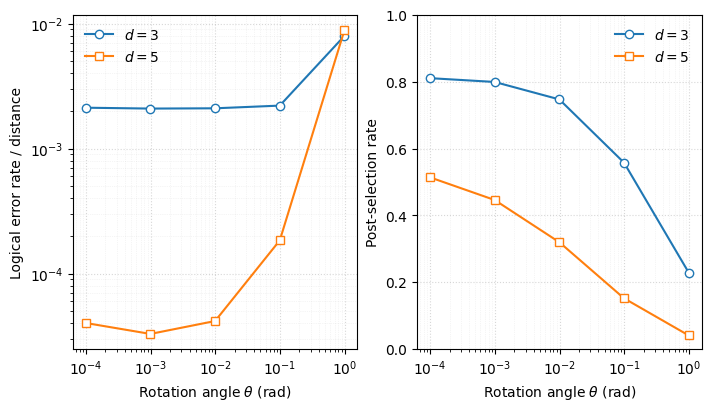

In [7]:
plot(logical_error_rate, post_selection_rate)

This essentially reproduces the results from the paper (with slightly different error model).

<img src="figures/star-ler.png" alt="arXiv:2509.18294" width=600/>